# COM7022 Machine Learning – Task 1: Clustering products by characteristics and sales performance

**Student ID:** _add your ID here_

**Goal.** Group the products in `Sales-[5444].csv` into segments that the business can act on (pricing, stock, promotion), using several clustering methods and comparing them.

Notebook outline
1. Setup and load
2. Data understanding and quality audit
3. Cleaning and feature engineering
4. Exploratory analysis
5. Feature selection and transformation (scaling, normalisation, categorical encoding)
6. Dimensionality reduction (PCA)
7. K-Means
8. Hierarchical (agglomerative) clustering
9. DBSCAN
10. Model comparison and stability
11. Sensitivity check: adding categorical features
12. Cluster profiles and business interpretation
13. Export

## 1. Setup and load

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42  # fixed seed so results are reproducible

# One colour per cluster, always in the same order; grey is reserved for DBSCAN noise
CLUSTER_COLOURS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
NOISE_COLOUR = '#9a9a96'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

In [ ]:
# The CSV must be in the same folder as this notebook. Both spellings of the file name are accepted.
import os
for name in ['Sales-5444.csv', 'Sales-[5444].csv', 'Sales_5444.csv']:
    if os.path.exists(name):
        DATA_FILE = name
        break
else:
    raise FileNotFoundError('Put Sales-5444.csv in this folder: ' + os.getcwd())
raw = pd.read_csv(DATA_FILE)
print('Shape:', raw.shape)
raw.head()

Shape: (1000, 10)


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


## 2. Data understanding and quality audit

In [ ]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    str    
 1   details            1000 non-null   str    
 2   Catatory           997 non-null    str    
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    str    
 5   available          889 non-null    float64
 6   text               997 non-null    str    
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    str    
 9   itemLocation       1000 non-null   str    
dtypes: float64(3), str(7)
memory usage: 78.3 KB


In [ ]:
# Missing values per column, as a count and a percentage
missing = pd.DataFrame({'missing': raw.isna().sum(),
                        'pct': (raw.isna().mean() * 100).round(1)})
missing

,missing,pct
Item_Name,1,0.1
details,0,0.0
Catatory,3,0.3
price,5,0.5
priceWithCurrency,1,0.1
available,111,11.1
text,3,0.3
sold,8,0.8
lastUpdated,53,5.3
itemLocation,0,0.0


In [ ]:
raw.describe()

,price,available,sold
count,995.000000,889.000000,992.000000
mean,46.433467,20.046119,775.246976
std,35.551712,61.547985,3211.433298
min,3.000000,2.000000,1.000000
25%,22.990000,5.000000,14.000000
50%,35.710000,10.000000,49.500000
75%,59.000000,10.000000,324.750000
max,259.090000,842.000000,54052.000000


In [ ]:
# Duplicate checks: exact duplicates, and same listing title at the same price
print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate (details, price) pairs:', raw.duplicated(subset=['details', 'price']).sum())

Exact duplicate rows: 0
Duplicate (details, price) pairs: 7


In [ ]:
# The 'Catatory' column (sic) is free text: many spellings of the same thing
print('Distinct category labels:', raw['Catatory'].nunique())
raw['Catatory'].value_counts().head(25)

Distinct category labels: 63


Catatory
Eau de Toilette                     444
Eau de Parfum                       285
Eau de Cologne                       56
Perfume                              50
Fragrances                           32
Eau De Parfum                        15
Parfum                               13
Eau de Perfume                       10
Eau De Toilette                       9
Gift Sets                             6
Cologne                               5
PARFUM                                4
Body Spray                            4
/                                     3
Aftershave                            3
Does not apply                        3
EDT                                   3
Parfum Intense                        3
LE PARFUM                             2
Eau De Parfum Intense                 2
Pheromone                             2
Fragrance Rolling Ball                2
Concentrated Uncut Pure Body Oil      1
Unscented                             1
~ THE ONE EAU DE PARFUM SPRAY ~

In [ ]:
# 'sold' should agree with the number embedded in the 'text' column. Check it.
sold_from_text = (raw['text'].str.extract(r'([\d,]+) sold')[0]
                  .str.replace(',', '').astype(float))
mismatch = raw[(sold_from_text != raw['sold']) & raw['sold'].notna()]
print('Rows where sold disagrees with text:', len(mismatch))
display(mismatch[['details', 'text', 'sold']])

# Price currency: almost all USD, a few Canadian dollars
print(raw['priceWithCurrency'].str.extract(r'^([A-Z]+ ?\$)')[0].value_counts())

Rows where sold disagrees with text: 1


,details,text,sold
7,Parfums De-Marly-Haltane Eau de Parfum spray 4...,Last One / 6 sold,7654.0


0
US $    996
C $       3
Name: count, dtype: int64


**Data quality issues found**

| Issue | Columns | Treatment (section 3) |
|---|---|---|
| Missing `price` (5 rows) but the value is present in `priceWithCurrency` | price | Recover from `priceWithCurrency` |
| 3 prices in Canadian dollars | price | Convert to USD at an assumed rate of 0.73 USD per CAD (May 2024) |
| Missing `sold` (8 rows), and one row where `sold` (7,654) contradicts `text` ("6 sold") | sold | Re-derive from `text`, which is the source string. No "sold" in text ⇒ 0 sold |
| `available` missing for "Last One" and "Limited quantity" listings | available | "Last One" ⇒ 1; "Limited quantity" ⇒ median + a flag column |
| "More than 10 available" is censored at 10 | available | Keep 10, note as a limitation |
| ~60 spellings of the category (EDT, Eau De Toilette, Eau de Toillette …) and junk values ("/", "Y", "Does not apply") | Catatory | Map to 6 clean groups |
| Missing `lastUpdated` (53 rows), mixed PDT/PST | lastUpdated | Parse to datetime, compute days since update, impute median + flag |
| Brand names in inconsistent case ("AS SHOW" vs "As Show") | Item_Name | Normalise case |
| Location is free text and sometimes contradictory ("Atlanta, Georgia, Canada") | itemLocation | Use the last token as country; reduce to US vs non-US |
| Bottle size buried in the title text | details | Extract size in oz (or ml ÷ 29.57) |

All three methods (K-Means, Ward hierarchical clustering and DBSCAN) group products by the distance between them in feature space. They take every value at face value and cannot tell a real value from a typing or scraping error. Each issue in the audit would therefore change the clusters directly rather than just adding noise.

- **The contradictory `sold` value (7,654 recorded, but the text says "6 sold").** `sold` is heavily skewed: the mean is 775 against a median of 49.5. One wrong value of this size would turn a one-off listing into an apparent best-seller. In K-Means it would drag a centroid towards it or form a fake cluster of its own, and in DBSCAN it would wrongly become noise. The `text` column is the original scraped string, so I treat it as the source of truth and re-derive `sold` from it. This also fills the 8 missing `sold` values: if the text contains no "sold" figure, the listing has 0 sales.
- **Missing prices (5 rows) and Canadian-dollar prices (3 rows).** Clustering cannot use missing values, and dropping rows wastes data when the price is still in `priceWithCurrency`. Mixing currencies is worse because it is silent: C$100 is only about US$73, so recording it as 100 would place it about 37% too high on the price axis. I convert at an assumed rate of 0.73 USD per CAD (May 2024).
- **`available` (111 missing, and capped at "More than 10").** Stock depth is one of the features that best separates high-volume sellers from one-off listings, so it cannot simply be ignored. "Last One" clearly means 1. "Limited quantity" has no number, so I impute the median and add a flag so the imputation stays traceable. The cap at 10 means the feature cannot tell 11 units from 800. I keep 10 and record this as a limitation.
- **63 category spellings and junk values ("/", "Does not apply").** Without mapping, "Eau de Toilette", "Eau De Toilette" and "EDT" would become separate categories. Any encoding would then split one product type into many sparse dummies. Mapping to 6 clean groups makes the category usable for profiling.
- **`lastUpdated` (53 missing, mixed PDT/PST).** Dates cannot be used in a distance calculation, so I convert them to a numeric "days since update" freshness measure. The missing values are imputed with the median and flagged, so they are not treated as up to date (0 days) by mistake.
- **Inconsistent brand case, contradictory locations, bottle size buried in the title.** These matter mostly for profiling and feature engineering. "AS SHOW" and "As Show" would count as different brands. Locations such as "Atlanta, Georgia, Canada" make city or state unreliable, so I keep only the country, reduced to US vs non-US. Bottle size is a real product characteristic (a 0.5 oz travel spray is not the same product as a 3.4 oz bottle), so I extract it from the title.

## 3. Cleaning and feature engineering

In [ ]:
df = raw.copy()

# --- Brand: tidy whitespace and case so 'AS SHOW' and 'As Show' are one brand
df['brand'] = (df['Item_Name'].fillna('Unknown').str.strip().str.title()
               .str.replace(r'\s*&\s*', ' & ', regex=True))

# --- Price: recover missing values from the currency string, then convert CAD to USD
price_from_text = df['priceWithCurrency'].str.extract(r'([\d.]+)')[0].astype(float)
df['price'] = df['price'].fillna(price_from_text)
CAD_TO_USD = 0.73  # assumed average rate for May 2024; state this assumption in the report
is_cad = df['priceWithCurrency'].str.startswith('C', na=False)
df.loc[is_cad, 'price'] = df.loc[is_cad, 'price'] * CAD_TO_USD

# --- Sold: the text column is the original string, so it is the source of truth
text = df['text'].fillna('')
df['sold'] = (text.str.extract(r'([\d,]+) sold')[0]
              .str.replace(',', '').astype(float).fillna(0))

# --- Available stock
avail = text.str.extract(r'(\d+) (?:lots )?available')[0].astype(float)
avail[text.str.startswith('Last One')] = 1
df['limited_qty_flag'] = text.str.startswith('Limited').astype(int)
df['available'] = avail.fillna(avail.median())

# --- Last updated -> days since update (relative to the newest record in the file)
parsed = pd.to_datetime(df['lastUpdated'].str.replace(r' P[SD]T$', '', regex=True),
                        format='%b %d, %Y %H:%M:%S', errors='coerce')
df['update_missing_flag'] = parsed.isna().astype(int)
df['days_since_update'] = (parsed.max() - parsed).dt.days
df['days_since_update'] = df['days_since_update'].fillna(df['days_since_update'].median())

# --- Country of the seller, and a simple US / non-US indicator
df['country'] = df['itemLocation'].str.split(',').str[-1].str.strip()
df['us_seller'] = (df['country'] == 'United States').astype(int)

# --- Bottle size in fluid ounces, from the listing title
oz = df['details'].str.extract(r'(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz', flags=re.I)[0].astype(float)
ml = df['details'].str.extract(r'(\d+(?:\.\d+)?)\s*ml', flags=re.I)[0].astype(float)
df['size_oz'] = oz.fillna(ml / 29.57)
df['size_oz'] = df['size_oz'].where(df['size_oz'].between(0.1, 12))  # drop implausible parses
df['size_oz'] = df['size_oz'].fillna(df['size_oz'].median())

In [ ]:
# --- Category: collapse ~60 free-text labels into 6 meaningful groups
def clean_category(label):
    s = str(label).lower()
    if any(k in s for k in ['toilette', 'toillette', 'edt']):
        return 'Eau de Toilette'
    if any(k in s for k in ['extrait', 'elixir', 'le parfum', 'parfum intense']) or s.strip() == 'parfum':
        return 'Parfum / Extrait'
    if any(k in s for k in ['parfum', 'perfume']):
        return 'Eau de Parfum'
    if any(k in s for k in ['cologne', 'edc', 'splash', 'aftershave']):
        return 'Cologne'
    if any(k in s for k in ['fragrance']):
        return 'Fragrance (unspecified)'
    return 'Other'  # gift sets, oils, body sprays, deodorant, junk values

df['category'] = df['Catatory'].apply(clean_category)
df['category'].value_counts()

category
Eau de Toilette            463
Eau de Parfum              363
Cologne                     74
Fragrance (unspecified)     36
Other                       33
Parfum / Extrait            31
Name: count, dtype: int64

In [ ]:
# Check the mapping on a sample so you can defend it
df.groupby('category')['Catatory'].unique().apply(lambda v: list(v)[:8])

category
Cologne                    [Eau de Cologne, Aftershave, Jo Malone Cologne...
Eau de Parfum              [Eau de Parfum, Perfume, Eau De Parfum, ~ THE ...
Eau de Toilette            [Eau de Toilette, Eau De Toilette, Eau de toil...
Fragrance (unspecified)    [Fragrances, Fragrance Rolling Ball, Fragrance...
Other                      [/, Concentrated Uncut Pure Body Oil, nan, Uns...
Parfum / Extrait           [PARFUM, Parfum, LE PARFUM, EXTRAIT DE PARFUM,...
Name: Catatory, dtype: object

In [ ]:
# Final check: no missing values remain in the fields we will model on
model_cols = ['price', 'sold', 'available', 'days_since_update', 'size_oz', 'category', 'us_seller']
print(df[model_cols].isna().sum())
print('Rows kept:', len(df))

price                0
sold                 0
available            0
days_since_update    0
size_oz              0
category             0
us_seller            0
dtype: int64
Rows kept: 1000


## 4. Exploratory analysis

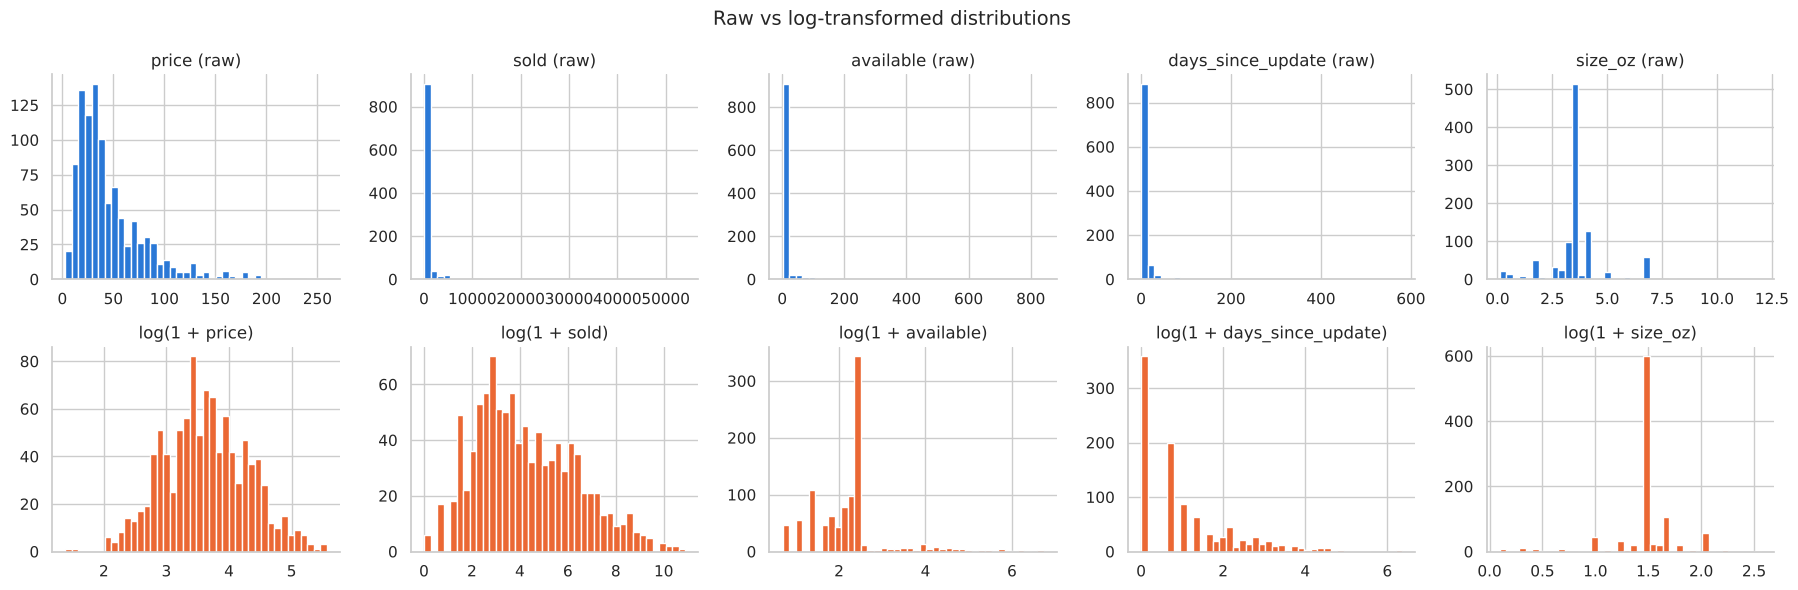

Skewness (raw):
price                 2.04
sold                  9.82
available             8.65
days_since_update    13.32
size_oz               0.82
dtype: float64


In [ ]:
num = ['price', 'sold', 'available', 'days_since_update', 'size_oz']
fig, axes = plt.subplots(2, len(num), figsize=(18, 6))
for i, col in enumerate(num):
    axes[0, i].hist(df[col], bins=40, color=CLUSTER_COLOURS[0])
    axes[0, i].set_title(f'{col} (raw)')
    axes[1, i].hist(np.log1p(df[col]), bins=40, color=CLUSTER_COLOURS[1])
    axes[1, i].set_title(f'log(1 + {col})')
fig.suptitle('Raw vs log-transformed distributions', fontsize=14)
plt.tight_layout(); plt.show()

print('Skewness (raw):'); print(df[num].skew().round(2))

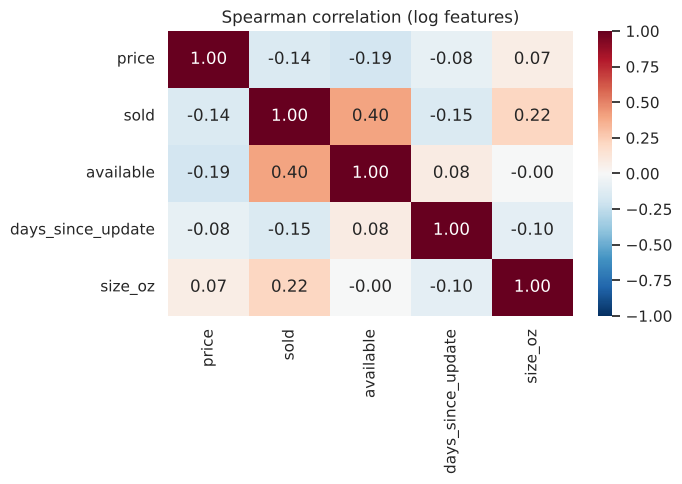

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
corr = np.log1p(df[num]).corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Spearman correlation (log features)')
plt.tight_layout(); plt.show()

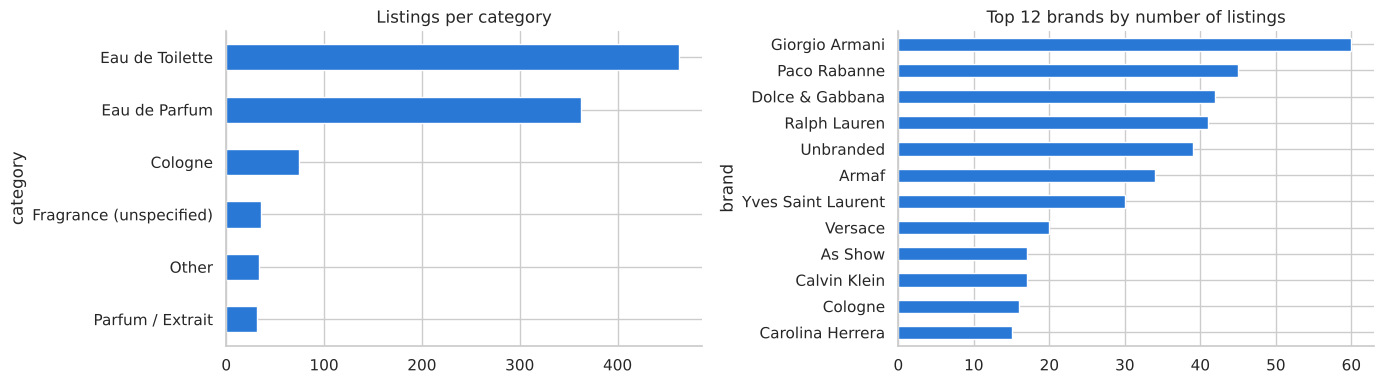

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['category'].value_counts().plot.barh(ax=axes[0], color=CLUSTER_COLOURS[0])
axes[0].set_title('Listings per category'); axes[0].invert_yaxis()
df['brand'].value_counts().head(12).plot.barh(ax=axes[1], color=CLUSTER_COLOURS[0])
axes[1].set_title('Top 12 brands by number of listings'); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

The histograms and skewness values show that the raw numeric features are far from symmetric. `days_since_update` (skew 13.32), `sold` (9.82) and `available` (8.65) are all heavily right-skewed, and `price` is moderately skewed (2.04). Only `size_oz` (0.82) is close to symmetric, because most bottles are the standard 3.4 oz. For `sold`, the median listing has 49.5 sales while the top five have 24,048 to 54,052. A small number of best-sellers sit orders of magnitude above everything else.

This matters for K-Means because it minimises **squared** Euclidean distance. On raw values, a product 50,000 units from the centroid adds 2.5 × 10⁹ to the objective, while the price difference between a $20 and a $200 bottle adds only 32,400. The model would then spend its clusters separating a handful of extreme sellers from the rest, and ignore real differences in price, freshness and size. Centroids, being means, would also be pulled towards the extremes and describe no typical product. The `log1p` transform fixes this: the log histograms are much closer to symmetric, so distances reflect relative differences (10 vs 100 sales counts as much as 100 vs 1,000).

**Correlation and double counting.** The Spearman matrix on the log features shows that the features are mostly weakly related. The strongest link is `sold` and `available` (ρ = 0.40): listings with more stock tend to have sold more, which fits large sellers stocking popular lines. PCA confirms this, as the two load together on PC1. Weaker links are `sold`–`size_oz` (0.22), `price`–`available` (−0.19), `sold`–`days_since_update` (−0.15) and `price`–`sold` (−0.14, cheaper items sell more). No pair is close to |ρ| ≈ 0.8, so no feature duplicates another, and I keep all five. Sales volume does get somewhat more weight because two partly correlated features describe it, and I bear this in mind when reading the clusters. For the same reason I did **not** add revenue (price × sold): it would put price and sales into the distance a second time.

## 5. Feature selection and transformation

**Features selected for the main model** (characteristics + sales performance, as the brief asks):

| Feature | Why include it |
|---|---|
| `price` | Core product characteristic; drives positioning |
| `sold` | The sales-performance measure |
| `available` | Stock position; separates high-volume sellers from one-off listings |
| `days_since_update` | Listing activity/freshness; stale listings are a business issue |
| `size_oz` | Product characteristic; separates samples/travel sizes from full bottles |

**Excluded:** `details` (free text; would need NLP), `priceWithCurrency` and `text` (duplicates of price/sold/available), `Item_Name`/brand (228 levels; one-hot would swamp the numeric features with sparse dimensions), raw `itemLocation` (free text, 90 % US so little variance), `revenue = price × sold` (a combination of two features already included, so it would double-weight them).

**Categorical variables.** `category` (6 groups) and `us_seller` are one-hot/binary encoded and tested in section 11 as a sensitivity check rather than in the main model, because binary dimensions tend to dominate distance-based clustering and split the data along the dummy variables instead of along behaviour.

**Transformations.**
1. `log1p` on all numeric features to reduce skew so a few extreme best-sellers don't dominate distances.
2. Standardisation (z-score) so every feature has mean 0 and sd 1 and contributes equally. Min-max normalisation is compared below.

In [ ]:
FEATURES = ['price', 'sold', 'available', 'days_since_update', 'size_oz']

X_log = np.log1p(df[FEATURES])
X_log.columns = [f'log_{c}' for c in FEATURES]

std_scaler = StandardScaler()
X = std_scaler.fit_transform(X_log)           # main matrix used for every model
X_minmax = MinMaxScaler().fit_transform(X_log)  # alternative, for comparison

pd.DataFrame(X, columns=X_log.columns).describe().round(2)

,log_price,log_sold,log_available,log_days_since_update,log_size_oz
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-3.34,-2.05,-1.67,-0.92,-4.35
25%,-0.67,-0.75,-0.66,-0.92,-0.01
50%,-0.04,-0.18,0.10,-0.34,0.07
75%,0.69,0.71,0.20,0.58,0.07
max,2.87,3.18,4.96,4.42,3.52


In [ ]:
# Does the choice of scaler matter? Compare K-Means (k=4) silhouette under each
for name, M in [('No scaling (log only)', X_log.values), ('Min-max', X_minmax), ('Standard', X)]:
    labels = KMeans(4, n_init=20, random_state=RANDOM_STATE).fit_predict(M)
    print(f'{name:22s} silhouette = {silhouette_score(M, labels):.3f}   '
          f'cluster sizes = {np.bincount(labels).tolist()}')

No scaling (log only)  silhouette = 0.285   cluster sizes = [286, 353, 175, 186]
Min-max                silhouette = 0.207   cluster sizes = [262, 195, 261, 282]


Standard               silhouette = 0.227   cluster sizes = [290, 432, 211, 67]


The silhouette scores for K-Means (k=4) are 0.285 with log only, 0.207 with min-max and 0.227 with standardisation. It is tempting to take the highest, but **these numbers cannot be compared fairly**. Silhouette is computed from distances in the space the model was fitted in, and each scaling creates a different space. A higher score in one space only says the clusters are better separated *in that space*. It does not say that space represents the products better.

The log-only result is high for a misleading reason. Without scaling, every feature keeps its own spread, and after the log transform `log_sold` covers about 10.9 units, while `log_size_oz` covers only 2.5 and `log_price` 4.2. Distance is then dominated by sales and stock, so K-Means mostly splits the data along one axis. This gives clean separation and a higher silhouette, but it barely uses price, freshness or size. That misses the point of the brief, which asks for clusters based on product *characteristics* as well as sales performance.

I chose **standardisation (z-scores)** on conceptual grounds:

1. **Equal weighting.** Each feature gets mean 0 and standard deviation 1, so a one-standard-deviation difference in price counts as much as one in sales. No feature dominates just because of its units.
2. **Robustness to the capped and extreme values.** Min-max scaling depends on the single minimum and maximum of each feature. `available` is capped at 10 for most rows, with a few very large stock values up to 842, so min-max squeezes most products into a narrow band near the bottom of the range. Standardisation depends on the mean and spread of all rows, so it is less sensitive to one extreme value.
3. **It suits the methods.** K-Means and Ward both assume roughly spherical, comparably scaled clusters, which z-scored features fit best. The scaled clusters (290 / 432 / 211 / 67 products) are also the ones that make the most business sense in section 12.

## 6. Dimensionality reduction (PCA)

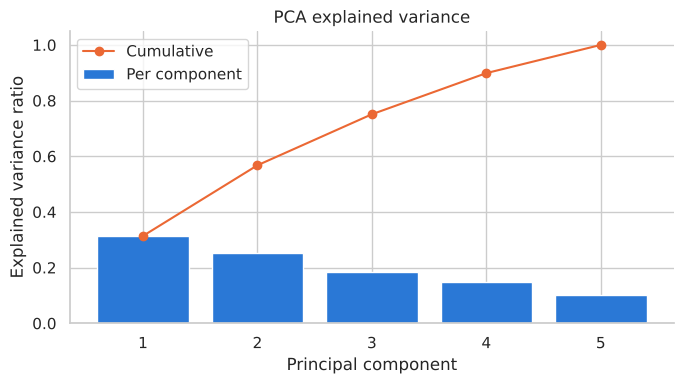

Cumulative variance, first 2 PCs: 56.8%, first 3: 75.1%


,PC1,PC2,PC3
log_price,-0.30,0.59,0.22
log_sold,0.67,0.11,0.02
log_available,0.63,-0.14,0.14
log_days_since_update,-0.15,-0.49,0.84
log_size_oz,0.19,0.62,0.48


In [ ]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(evr) + 1), evr, color=CLUSTER_COLOURS[0], label='Per component')
ax.plot(range(1, len(evr) + 1), np.cumsum(evr), marker='o', color=CLUSTER_COLOURS[1], label='Cumulative')
ax.set_xlabel('Principal component'); ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA explained variance'); ax.legend()
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=X_log.columns, columns=['PC1', 'PC2', 'PC3'])
print('Cumulative variance, first 2 PCs: {:.1%}, first 3: {:.1%}'.format(evr[:2].sum(), evr[:3].sum()))
loadings.round(2)

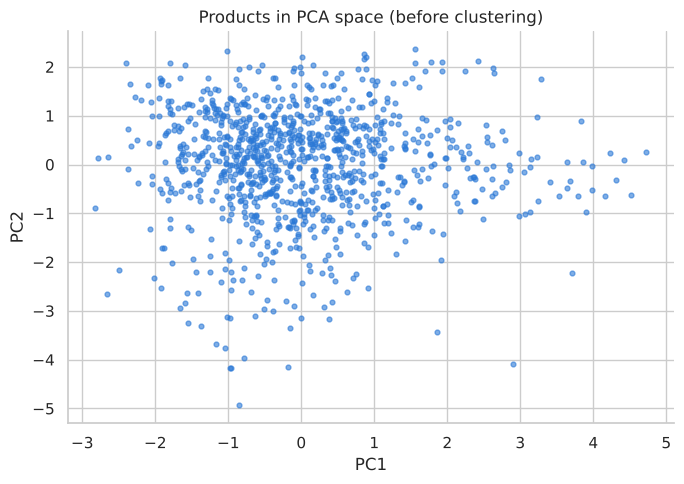

In [ ]:
X_pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

def plot_clusters(labels, title, ax=None):
    # Scatter of the 2-D PCA projection, one fixed colour per cluster, noise in grey
    ax = ax or plt.subplots(figsize=(7, 5))[1]
    for k in sorted(set(labels)):
        m = labels == k
        colour = NOISE_COLOUR if k == -1 else CLUSTER_COLOURS[k % len(CLUSTER_COLOURS)]
        name = 'Noise' if k == -1 else f'Cluster {k}'
        ax.scatter(X_pca2[m, 0], X_pca2[m, 1], s=14, alpha=0.7, color=colour,
                   label=f'{name} (n={m.sum()})', edgecolor='white', linewidth=0.3)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.legend(fontsize=8)
    return ax

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_pca2[:, 0], X_pca2[:, 1], s=12, alpha=0.6, color=CLUSTER_COLOURS[0])
ax.set_title('Products in PCA space (before clustering)'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout(); plt.show()

The first two principal components explain 56.8% of the variance in the five standardised features, and the first three explain 75.1%. The loadings show what each component means:

- **PC1 is sales volume and stock depth.** It loads strongly on `log_sold` (0.67) and `log_available` (0.63), with a negative loading on price (−0.30). Products on the right of the scatter plot sell a lot, hold more stock and tend to be cheaper.
- **PC2 is product type and listing freshness.** It loads positively on `log_size_oz` (0.62) and `log_price` (0.59) and negatively on `log_days_since_update` (−0.49). High PC2 values are larger, more expensive bottles in recently updated listings. Low values are small or cheap items, or listings that have not been updated for a while.
- **PC3 is mostly freshness.** It is dominated by `log_days_since_update` (0.84), with some size (0.48). This shows that listing staleness is a dimension of its own that the first two components do not fully capture.

**Why PCA is used for visualisation, not for clustering.** I use the 2-D projection only to *plot* the products and the clusters, because a 5-D space cannot be drawn. The clustering itself runs on all five scaled features, for three reasons. First, with only five features there is no "curse of dimensionality" to fix, and K-Means handles 5 dimensions easily. Second, keeping only two components would throw away 43.2% of the variance, including most of the freshness signal on PC3, and the stale-listing segment found later would become harder to see. Third, clusters defined on the original features are much easier to explain to the business ("high sales, low price") than clusters defined on abstract components. One caveat: overlap in the 2-D plot does not mean the clusters overlap in 5-D. Some points that look mixed are separated along PC3–PC5. A possible extension is to cluster on the first 3 PCs (75% of variance) and compare the result with ARI.

## 7. K-Means

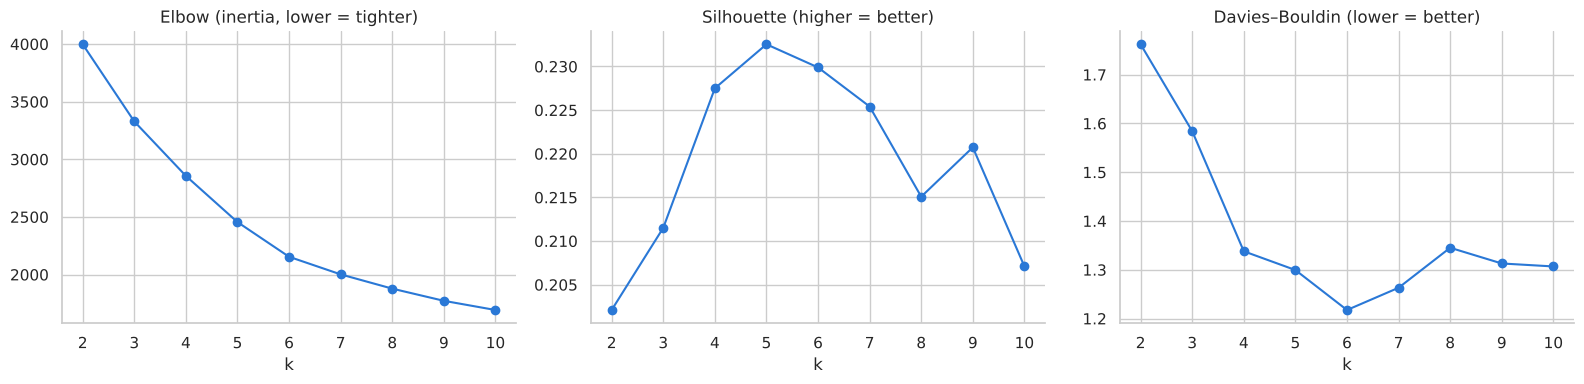

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,3998.060,0.202,1.762,250.109
3,3328.429,0.212,1.584,250.352
4,2856.028,0.227,1.338,249.227
5,2455.279,0.233,1.299,257.812
6,2154.378,0.230,1.218,262.586
7,2001.728,0.225,1.263,247.893
8,1877.945,0.215,1.345,235.598
9,1772.325,0.221,1.313,225.595
10,1692.589,0.207,1.307,214.946


In [ ]:
k_range = range(2, 11)
rows = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    rows.append({'k': k, 'inertia': km.inertia_,
                 'silhouette': silhouette_score(X, km.labels_),
                 'davies_bouldin': davies_bouldin_score(X, km.labels_),
                 'calinski_harabasz': calinski_harabasz_score(X, km.labels_)})
k_scores = pd.DataFrame(rows).set_index('k')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(k_scores.index, k_scores['inertia'], marker='o', color=CLUSTER_COLOURS[0]); axes[0].set_title('Elbow (inertia, lower = tighter)')
axes[1].plot(k_scores.index, k_scores['silhouette'], marker='o', color=CLUSTER_COLOURS[0]); axes[1].set_title('Silhouette (higher = better)')
axes[2].plot(k_scores.index, k_scores['davies_bouldin'], marker='o', color=CLUSTER_COLOURS[0]); axes[2].set_title('Davies–Bouldin (lower = better)')
for a in axes: a.set_xlabel('k')
plt.tight_layout(); plt.show()
k_scores.round(3)

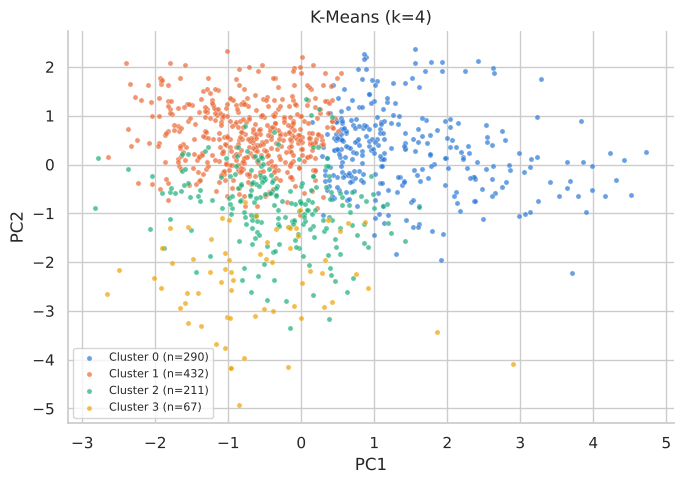

In [ ]:
K = 4  # chosen from the elbow + silhouette + DB plots and interpretability
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
df['kmeans'] = kmeans.labels_
plot_clusters(df['kmeans'].values, f'K-Means (k={K})'); plt.tight_layout(); plt.show()

The three diagnostics do not give one obvious answer, as is common with real data:

| k | Inertia | Silhouette ↑ | Davies–Bouldin ↓ | Calinski–Harabasz ↑ |
|---|---|---|---|---|
| 3 | 3,328 | 0.212 | 1.584 | 250.4 |
| **4** | **2,856** | **0.227** | **1.338** | **249.2** |
| 5 | 2,455 | 0.233 | 1.299 | 257.8 |
| 6 | 2,154 | 0.230 | 1.218 | 262.6 |

- **Elbow.** Inertia falls fastest from k=2 to k=4 (−1,142) and the drops then shrink (−401 from 4 to 5, −301 from 5 to 6). The curve bends around k=4–5.
- **Silhouette** peaks at k=5 (0.233), but k=4 (0.227) is only 0.006 lower. That gap is within what a different random start or a bootstrap sample would produce.
- **Davies–Bouldin** improves slightly at k=5 (1.299 vs 1.338) and keeps improving to k=6. DB tends to reward more, smaller clusters, so it cannot decide this on its own.
- **Calinski–Harabasz** is nearly flat from k=2 to k=5.

On the metrics alone, k=4 and k=5 are effectively tied. **I chose k=4** and let business usefulness break the tie. The four clusters form clearly different groups that map onto four separate actions (protect and restock, reprice or promote, refresh or relist, bundle and cross-sell; see section 12). A fifth cluster mostly splits an existing segment along a dimension with no new action attached. Every extra segment means another strategy for merchandisers to own and track, so a smaller set of clearly different groups is easier to act on and explain. k=4 is also close to the best value on every metric, and section 10 shows it is stable (bootstrap ARI 0.875). Using k=4 for the hierarchical model as well gives a like-for-like comparison.

## 8. Hierarchical (agglomerative) clustering

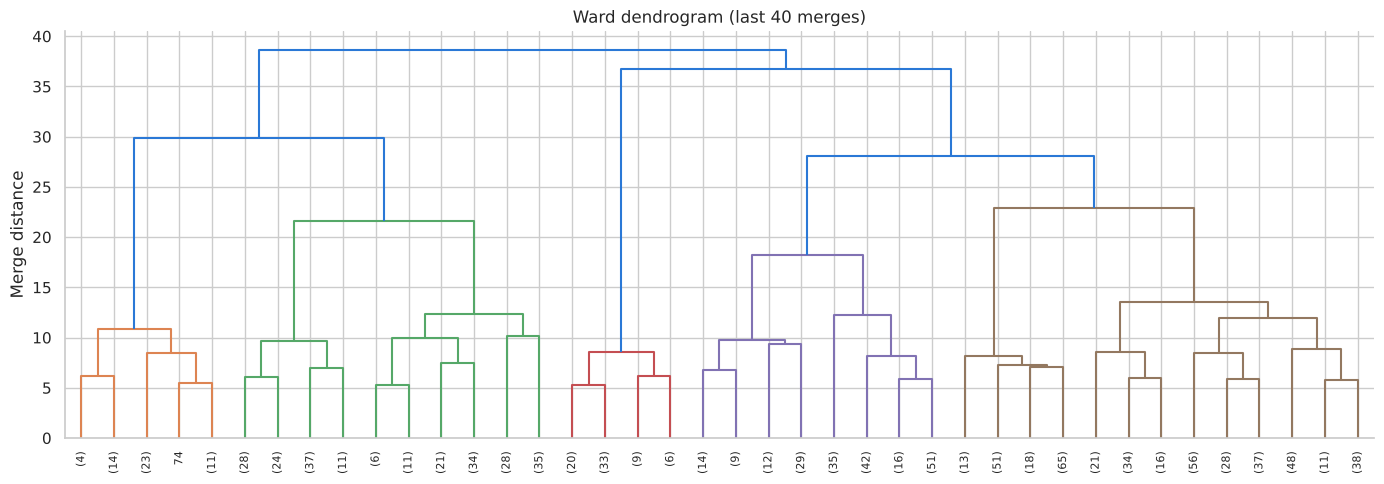

In [ ]:
# Dendrogram using Ward linkage (merges clusters that least increase within-cluster variance)
Z = linkage(X, method='ward')
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=40, leaf_rotation=90, ax=ax, color_threshold=None,
           above_threshold_color=CLUSTER_COLOURS[0])
ax.set_title('Ward dendrogram (last 40 merges)'); ax.set_ylabel('Merge distance')
plt.tight_layout(); plt.show()

In [ ]:
# Compare linkage criteria across k
rows = []
for method in ['ward', 'complete', 'average']:
    for k in range(2, 9):
        lab = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        rows.append({'linkage': method, 'k': k,
                     'silhouette': silhouette_score(X, lab),
                     'davies_bouldin': davies_bouldin_score(X, lab),
                     'smallest_cluster': np.bincount(lab).min()})
hier_scores = pd.DataFrame(rows)
hier_scores.pivot(index='k', columns='linkage', values=['silhouette', 'smallest_cluster']).round(3)

silhouette                 smallest_cluster                
linkage    average complete   ward          average complete   ward
k                                                                  
2            0.502    0.325  0.200              2.0     81.0  288.0
3            0.352    0.284  0.225              2.0     59.0   68.0
4            0.332    0.272  0.223              1.0      9.0   53.0
5            0.261    0.168  0.192              1.0      9.0   53.0
6            0.265    0.144  0.163              1.0      9.0   53.0
7            0.253    0.141  0.178              1.0      9.0   53.0
8            0.218    0.133  0.187              1.0      9.0   53.0

Average and complete linkage often get high silhouettes by putting nearly everything in one cluster and isolating a few outliers (look at `smallest_cluster`). That is not useful segmentation, so Ward is preferred.

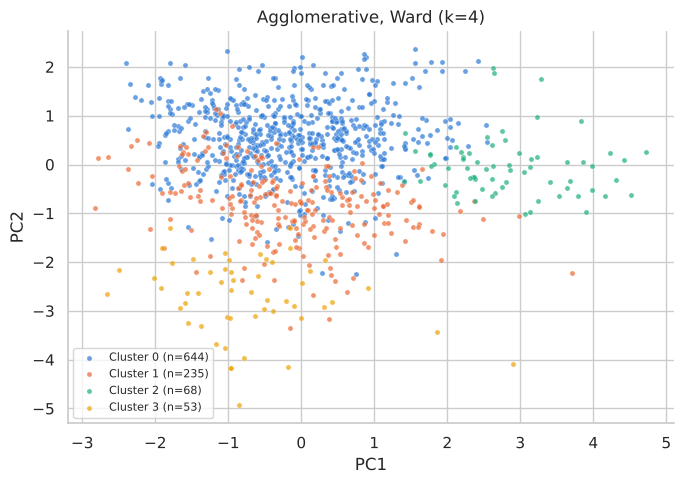

In [ ]:
hier = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X)
df['hierarchical'] = hier.labels_
plot_clusters(df['hierarchical'].values, f'Agglomerative, Ward (k={K})'); plt.tight_layout(); plt.show()

## 9. DBSCAN

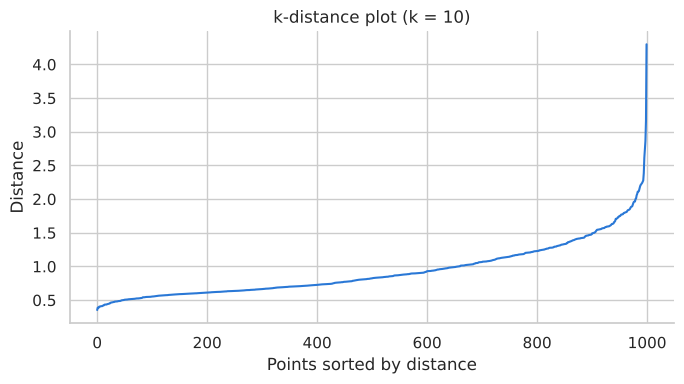

In [ ]:
# Choose eps with the k-distance plot: distance to each point's MIN_SAMPLES-th neighbour, sorted.
# The 'knee' of the curve is a sensible eps. Rule of thumb: min_samples ≈ 2 × number of features.
MIN_SAMPLES = 2 * X.shape[1]
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(kdist, color=CLUSTER_COLOURS[0])
ax.set_title(f'k-distance plot (k = {MIN_SAMPLES})'); ax.set_xlabel('Points sorted by distance'); ax.set_ylabel('Distance')
plt.tight_layout(); plt.show()

In [ ]:
rows = []
for eps in np.arange(0.5, 1.45, 0.1):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    core = lab != -1
    n_clusters = len(set(lab[core]))
    sil = silhouette_score(X[core], lab[core]) if n_clusters > 1 else np.nan
    rows.append({'eps': round(eps, 2), 'clusters': n_clusters,
                 'noise_pct': round(100 * (~core).mean(), 1), 'silhouette_excl_noise': sil})
dbscan_scores = pd.DataFrame(rows)
dbscan_scores.round(3)

,eps,clusters,noise_pct,silhouette_excl_noise
0,0.5,7,84.6,0.396
1,0.6,2,62.7,0.342
2,0.7,2,46.1,0.172
3,0.8,3,35.4,0.182
4,0.9,3,25.9,0.185
5,1.0,1,18.8,NaN
6,1.1,1,14.4,NaN
7,1.2,2,8.8,0.416
8,1.3,2,5.2,0.405
9,1.4,2,3.4,0.405


eps=1.2: {0: 898, -1: 88, 1: 14}


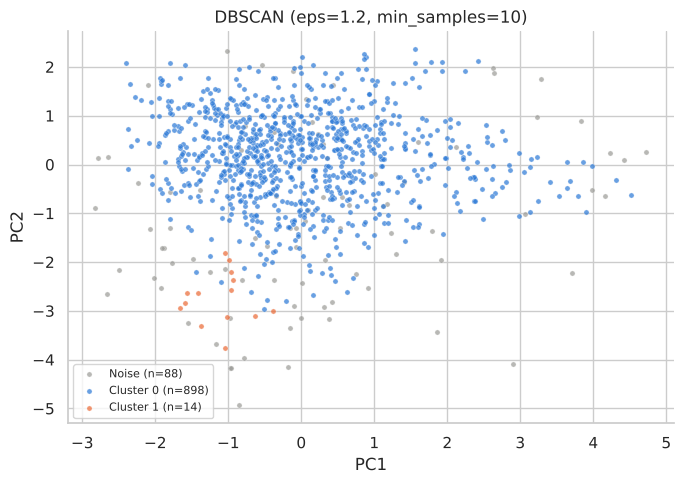

In [ ]:
# Pick the eps that gives >1 cluster with the best silhouette and noise under ~20 %
candidates = dbscan_scores[(dbscan_scores.clusters > 1) & (dbscan_scores.noise_pct < 20)]
EPS = candidates.sort_values('silhouette_excl_noise', ascending=False)['eps'].iloc[0]
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
df['dbscan'] = dbscan.labels_
print(f'eps={EPS}:', df['dbscan'].value_counts().to_dict())
plot_clusters(df['dbscan'].values, f'DBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})'); plt.tight_layout(); plt.show()

With `min_samples = 10` and `eps = 1.2` (chosen from the k-distance plot and the eps grid), DBSCAN finds **one dominant cluster of 898 products, one small cluster of 14 and 88 noise points (8.8%)**. The eps grid explains why. Small eps values (0.5–0.7) break the data into fragments and leave 46–85% of products unassigned. Larger values (1.0–1.1) merge everything into a single cluster. No setting gives several balanced segments. This tells us something real about the data: the products form **one continuous dense mass** with no low-density gaps between natural groups. DBSCAN can only separate groups that have such gaps, so it has nothing to cut.

The silhouette of 0.416 is the highest of any model, but it is flattering. It is computed *after removing the noise points*, which are the hardest cases, and comparing one huge cluster with a tiny distant one is an easy contrast. So it does not mean DBSCAN segments the catalogue better.

**For segmentation, the result is a failure.** One group containing 90% of products gives the business nothing to act on.

**As an anomaly detector it is useful.** The noise points are the listings that sit outside the main density, and they include the most commercially important exceptions: 7 of the 88 have over 5,000 units sold, and 16 hold more than 50 units of stock. These are exactly the products a merchandiser should review by hand: top sellers to protect, unusually large stock positions to check, and possible data errors. The small 14-product cluster is also distinct: median size 0.33 oz, median 7 sold, mostly Eau de Parfum, so it is mainly sample-size or mini listings.

My conclusion is that DBSCAN is the wrong tool for the main segmentation but a useful complement. Its noise label can be kept as an "exceptions" flag alongside the K-Means segments. HDBSCAN, which handles varying density, would be worth trying in future work.

## 10. Model comparison and stability

In [ ]:
def evaluate(name, labels, M=X):
    core = labels != -1
    n = len(set(labels[core]))
    out = {'model': name, 'clusters': n, 'noise_pct': round(100 * (~core).mean(), 1)}
    if n > 1:
        out.update({'silhouette': silhouette_score(M[core], labels[core]),
                    'davies_bouldin': davies_bouldin_score(M[core], labels[core]),
                    'calinski_harabasz': calinski_harabasz_score(M[core], labels[core])})
    out['smallest_cluster'] = np.bincount(labels[core]).min()
    return out

comparison = pd.DataFrame([
    evaluate(f'K-Means (k={K})', df['kmeans'].values),
    evaluate(f'Agglomerative Ward (k={K})', df['hierarchical'].values),
    evaluate(f'DBSCAN (eps={EPS})', df['dbscan'].values),
]).set_index('model')
comparison.round(3)

,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
model,,,,,,
K-Means (k=4),4,0.0,0.227,1.338,249.227,67
Agglomerative Ward (k=4),4,0.0,0.223,1.408,197.542,53
DBSCAN (eps=1.2),2,8.8,0.416,0.671,57.875,14


In [ ]:
# Stability: refit each model on 20 bootstrap samples (80 % of rows) and compare the labels
# it gives with the full-data labels on the same rows (Adjusted Rand Index; 1 = identical).
rng = np.random.default_rng(RANDOM_STATE)
stab = {'K-Means': [], 'Agglomerative': [], 'DBSCAN': []}
for _ in range(20):
    idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    Xb = X[idx]
    stab['K-Means'].append(adjusted_rand_score(df['kmeans'].values[idx],
        KMeans(K, n_init=10, random_state=int(rng.integers(1e6))).fit_predict(Xb)))
    stab['Agglomerative'].append(adjusted_rand_score(df['hierarchical'].values[idx],
        AgglomerativeClustering(K, linkage='ward').fit_predict(Xb)))
    stab['DBSCAN'].append(adjusted_rand_score(df['dbscan'].values[idx],
        DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Xb)))
stability = pd.DataFrame(stab).agg(['mean', 'std']).T.round(3)
comparison['stability_ARI'] = stability['mean'].values
comparison.round(3)

,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster,stability_ARI
model,,,,,,,
K-Means (k=4),4,0.0,0.227,1.338,249.227,67,0.875
Agglomerative Ward (k=4),4,0.0,0.223,1.408,197.542,53,0.532
DBSCAN (eps=1.2),2,8.8,0.416,0.671,57.875,14,0.879


ARI K-Means vs Agglomerative: 0.385
Crosstab:


Ward,0,1,2,3
K-Means,,,,
0,187,35,68,0
1,413,19,0,0
2,27,180,0,4
3,17,1,0,49


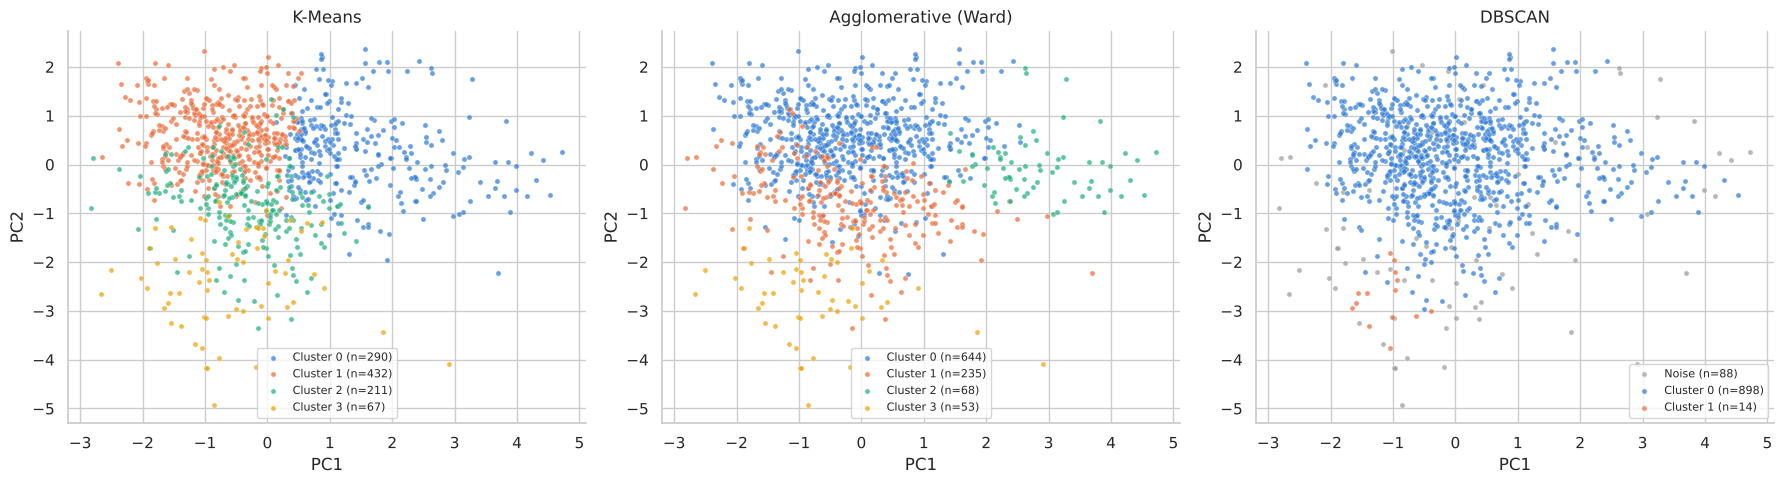

In [ ]:
# Agreement between methods (how similar are the partitions?)
print('ARI K-Means vs Agglomerative:', round(adjusted_rand_score(df['kmeans'], df['hierarchical']), 3))
print('Crosstab:'); display(pd.crosstab(df['kmeans'], df['hierarchical'], rownames=['K-Means'], colnames=['Ward']))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_clusters(df['kmeans'].values, 'K-Means', axes[0])
plot_clusters(df['hierarchical'].values, 'Agglomerative (Ward)', axes[1])
plot_clusters(df['dbscan'].values, 'DBSCAN', axes[2])
plt.tight_layout(); plt.show()

| Criterion | K-Means (k=4) | Agglomerative Ward (k=4) | DBSCAN (eps=1.2) |
|---|---|---|---|
| Clusters / noise | 4 / 0% | 4 / 0% | 2 / 8.8% |
| Silhouette ↑ | 0.227 | 0.223 | 0.416* |
| Davies–Bouldin ↓ | 1.338 | 1.408 | 0.671* |
| Calinski–Harabasz ↑ | **249.2** | 197.5 | 57.9 |
| Stability (bootstrap ARI) ↑ | **0.875** | 0.532 | 0.879 |
| Smallest cluster | 67 | 53 | 14 |

\*computed with noise points removed, so not directly comparable

**(a) Internal validity.** K-Means and Ward have almost the same silhouette (0.227 vs 0.223), but K-Means is better on Davies–Bouldin (1.338 vs 1.408) and clearly better on Calinski–Harabasz (249 vs 198), so its clusters are more compact relative to how far apart they are. DBSCAN's better silhouette and DB come from removing the 88 hardest points and comparing one huge cluster with one tiny one (see section 9). Its very low CH (57.9) shows it explains little of the overall structure.

All the silhouettes are **modest (about 0.22)**. On a −1 to 1 scale, this means the clusters are real but overlap. That is typical of real product data: prices, sales and stock vary smoothly, and there are no natural "types" with gaps between them. The clusters are best described as **segments along a continuum**: useful groupings for decisions, not discrete natural kinds. I state this openly rather than presenting the clusters as sharper than they are.

**(b) Stability.** Refitting on 20 bootstrap samples of 80% of the rows, K-Means reproduces its own labels with mean ARI 0.875, so the segments do not depend on which products happen to be in the sample. Ward is much less stable (0.532). Its merges are greedy and cannot be undone, so small changes in the data can change early merges and alter the final partition. DBSCAN's 0.879 is high only because "almost everything in one cluster" is easy to reproduce. K-Means and Ward agree with each other only moderately (ARI 0.385). The crosstab shows that most of the disagreement is about where K-Means cluster 0 ends, which is expected along a continuum.

**(c) Cluster balance.** K-Means gives segments of 290 / 432 / 211 / 67 products, all large enough to act on. Ward is similarly balanced (smallest 53). DBSCAN gives 898 / 14, which is too unbalanced to use.

**(d) Business usefulness.** K-Means assigns **every** product to a segment, unlike DBSCAN, which leaves 88 unassigned. Its centroids are averages that a manager can read directly ("cheaper, high sales, well stocked"). It scales to the full catalogue: it is roughly linear in the number of products, while Ward needs a full pairwise distance matrix. And `kmeans.predict()` can label **new** products as they are listed without refitting, which agglomerative clustering cannot do.

**Final choice: K-Means with k = 4.** On technical grounds it has the best combination of validity (best CH and DB of the two models that cover every product), stability (ARI 0.875) and balance. On business grounds it is easy to explain, covers the whole catalogue and can be put into production. I keep DBSCAN's noise label as a separate exceptions flag, and I use Ward's dendrogram as supporting evidence that a solution with about 4 clusters is reasonable.

## 11. Sensitivity check: adding categorical features

In [ ]:
# One-hot encode the cleaned category and add the US-seller flag to the scaled numeric features
try:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')  # scikit-learn 1.2+
except TypeError:
    ohe = OneHotEncoder(sparse=False, handle_unknown='ignore')         # older scikit-learn
cat = ohe.fit_transform(df[['category']])
X_cat = np.hstack([X, cat, df[['us_seller']].values])
print('Feature matrix with categoricals:', X_cat.shape)

km_cat = KMeans(K, n_init=20, random_state=RANDOM_STATE).fit_predict(X_cat)
print('Silhouette with categoricals:', round(silhouette_score(X_cat, km_cat), 3))
print('ARI vs numeric-only K-Means:', round(adjusted_rand_score(df['kmeans'], km_cat), 3))
pd.crosstab(km_cat, df['category'], rownames=['cluster (with categoricals)'])

Feature matrix with categoricals: (1000, 12)
Silhouette with categoricals: 0.191
ARI vs numeric-only K-Means: 0.851


category,Cologne,Eau de Parfum,Eau de Toilette,Fragrance (unspecified),Other,Parfum / Extrait
cluster (with categoricals),,,,,,
0,28,184,147,30,16,19
1,18,54,197,2,4,3
2,11,35,17,2,4,1
3,17,90,102,2,9,8


Adding the six one-hot category columns and the US-seller flag (12 features in total) **barely changes the clusters**. The ARI against the numeric-only K-Means is 0.851, so about 85% of the pairwise grouping agrees once chance agreement is removed. The silhouette **falls** from 0.227 to 0.191, so the clusters become less well separated.

The crosstab shows the clusters did **not** start following category. Every cluster still contains a mix of Eau de Toilette, Eau de Parfum and Cologne. For example, the largest cluster has 184 Eau de Parfum and 147 Eau de Toilette products, and another has 90 EDP and 102 EDT. The partition is still driven by price, sales, stock, freshness and size. The dummies add seven extra dimensions without creating new, meaningful structure, which explains the lower silhouette. There is also a methodological problem. A 0/1 dummy is not on the same scale as a z-scored continuous feature: the distance between any two categories is always √2, however similar the products are. If the dummies had more weight, K-Means would tend to split by category, which would just reproduce a label the business already has.

This justifies the design choice: **keep categorical variables out of the main model and use them for profiling** (section 12). The clusters then describe *behaviour*, and the category mix of each cluster becomes a finding rather than an input. For example, the minis cluster has more Cologne (16.4%), while the high-volume cluster is mostly Eau de Toilette (63.8%).

If categoricals did need to be inside the model, there are methods designed for mixed data. **K-Prototypes** combines K-Means on the numeric features with K-Modes on the categorical ones, using a weight γ to balance them. Alternatively, **Gower distance** scales each feature type to [0, 1] and can then be used with hierarchical clustering or PAM (k-medoids). Either would be a sensible extension.

## 12. Cluster profiles and business interpretation (final model: K-Means)

In [ ]:
FINAL = 'kmeans'
profile = df.groupby(FINAL).agg(
    products=('price', 'size'),
    median_price=('price', 'median'),
    median_sold=('sold', 'median'),
    total_sold=('sold', 'sum'),
    median_available=('available', 'median'),
    median_days_since_update=('days_since_update', 'median'),
    median_size_oz=('size_oz', 'median'),
    pct_us_seller=('us_seller', 'mean'),
)
profile['share_of_units_sold_%'] = 100 * profile['total_sold'] / profile['total_sold'].sum()
profile['est_revenue'] = df.assign(rev=df.price * df.sold).groupby(FINAL)['rev'].sum()
profile.round(2)

,products,median_price,median_sold,total_sold,median_available,median_days_since_update,median_size_oz,pct_us_seller,share_of_units_sold_%,est_revenue
kmeans,,,,,,,,,,
0,290,29.76,635.0,689606.0,10.0,0.0,3.4,0.99,90.54,23024333.85
1,432,49.99,20.0,23128.0,5.0,1.0,3.4,0.86,3.04,1769203.18
2,211,29.99,31.0,21965.0,10.0,15.0,3.4,0.90,2.88,716196.41
3,67,20.00,20.0,26970.0,10.0,2.0,0.5,0.97,3.54,298244.53


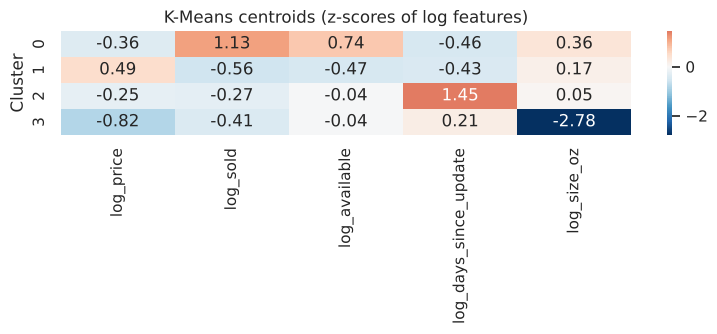

In [ ]:
# Standardised centroids: how far each cluster sits above/below the average on each feature
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=X_log.columns)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(centroids, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('K-Means centroids (z-scores of log features)'); ax.set_ylabel('Cluster')
plt.tight_layout(); plt.show()

/tmp/ipykernel_259/4020995806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in range(K)], ax=ax, showfliers=False)
/tmp/ipykernel_259/4020995806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in range(K)], ax=ax, showfliers=False)
/tmp/ipykernel_259/4020995806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in r

/tmp/ipykernel_259/4020995806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in range(K)], ax=ax, showfliers=False)


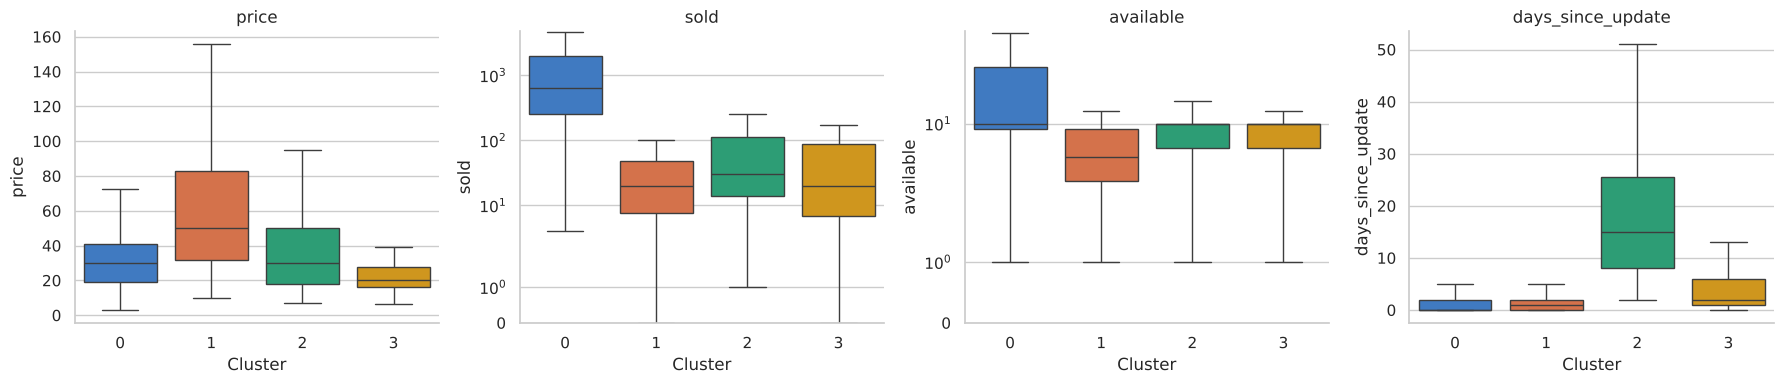

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
palette = {k: CLUSTER_COLOURS[k] for k in range(K)}
for ax, col in zip(axes, ['price', 'sold', 'available', 'days_since_update']):
    sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in range(K)], ax=ax, showfliers=False)
    ax.set_title(col); ax.set_xlabel('Cluster')
    if col in ('sold', 'available'):
        ax.set_yscale('symlog')
        ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

In [ ]:
# Category mix (%) and top brands per cluster: categorical variables used for profiling
display((pd.crosstab(df[FINAL], df['category'], normalize='index') * 100).round(1))
for k in range(K):
    print(f'Cluster {k} top brands:', df.loc[df[FINAL] == k, 'brand'].value_counts().head(6).to_dict())

category,Cologne,Eau de Parfum,Eau de Toilette,Fragrance (unspecified),Other,Parfum / Extrait
kmeans,,,,,,
0,6.9,24.1,63.8,1.4,2.1,1.7
1,6.9,39.8,38.7,6.7,3.5,4.4
2,6.2,41.7,44.5,0.5,4.3,2.8
3,16.4,49.3,25.4,3.0,4.5,1.5


Cluster 0 top brands: {'Armaf': 16, 'Ralph Lauren': 14, 'Dolce & Gabbana': 13, 'Giorgio Armani': 13, 'Calvin Klein': 10, 'Azzaro': 9}
Cluster 1 top brands: {'Giorgio Armani': 35, 'Paco Rabanne': 28, 'Dolce & Gabbana': 21, 'Unbranded': 17, 'Yves Saint Laurent': 17, 'As Show': 15}
Cluster 2 top brands: {'Ralph Lauren': 10, 'Unbranded': 8, 'Giorgio Armani': 8, 'Paco Rabanne': 8, 'Dolce & Gabbana': 6, 'Armaf': 6}
Cluster 3 top brands: {'Unbranded': 7, 'Dossier': 5, 'Giorgio Armani': 4, 'Yves Saint Laurent': 4, 'Hermes': 3, 'Ralph Lauren': 3}


I checked each name against both the profile table (medians in original units) and the centroid heatmap (z-scores of the log features; positive means above the catalogue average).

| Cluster | Products | Profile (medians) | Centroid signature (z) | Business name |
|---|---|---|---|---|
| 0 | 290 (29%) | $29.76, 635 sold, 10 available, 0 days since update, 3.4 oz | sold **+1.13**, available **+0.74**, price −0.36 | **High-volume best-sellers** |
| 1 | 432 (43%) | **$49.99**, 20 sold, **5 available**, 1 day, 3.4 oz | price **+0.49**, sold **−0.56**, available **−0.47** | **Premium slow movers** |
| 2 | 211 (21%) | $29.99, 31 sold, 10 available, **15 days**, 3.4 oz | days since update **+1.45** | **Stale listings** |
| 3 | 67 (7%) | **$20.00**, 20 sold, 10 available, 2 days, **0.5 oz** | size **−2.78**, price **−0.82** | **Travel-size and minis** |

**Cluster 0: High-volume best-sellers.** Only 29% of listings, but **90.5% of all units sold** and about **$23.0M of estimated revenue** (more than all the other clusters combined). These are well-priced mainstream bottles (Armaf, Ralph Lauren, Dolce & Gabbana, Giorgio Armani), mostly Eau de Toilette (63.8%), with deep stock and listings kept up to date.
*Action: **restock and protect.** Set automatic reorder points so these never go out of stock, give them priority placement, and avoid unnecessary discounting because they already sell at this price. Any stock-out here directly costs revenue.*

**Cluster 1: Premium slow movers.** The largest segment (432 products) has the highest median price ($49.99) but a median of only 20 units sold, accounting for just 3.0% of units. Stock is also the thinnest (median 5). It includes premium designer lines (Giorgio Armani, Paco Rabanne, YSL) and a higher share of Eau de Parfum (39.8%).
*Action: **reprice or promote.** Test targeted price cuts or bundle offers on the highest-priced items and compare against competitors' prices. Keep stock lean rather than buying in depth, and review margins to see which lines are worth keeping.*

**Cluster 2: Stale listings.** Mid-priced ($29.99) with modest sales (31), but these listings have not been updated for a median of **15 days**. The other clusters are at 0–2 days, and a quarter of this cluster is over 25 days old. They are otherwise similar to the core range, so the problem is listing activity rather than the product.
*Action: **refresh, relist or delist.** Update photos, titles and prices, and relist to regain search visibility. Delist items that stay inactive after a set review period so they stop taking up catalogue and stock.*

**Cluster 3: Travel-size and minis.** A small, clearly distinct segment: median bottle size 0.5 oz against 3.4 oz everywhere else, the lowest price ($20), and modest sales (20). It has more Cologne (16.4%) and more unbranded or sample sellers (Dossier, Unbranded).
*Action: **bundle and cross-sell.** Position these as add-ons and gift sets ("try before you buy") alongside the full-size best-sellers in Cluster 0, and use them in checkout and seasonal gift promotions. They are low in value individually, so selling them on their own is unlikely to pay off.*

**Caveats for the executive report.** `sold` is lifetime sales with no time window, and `available` is capped at 10, so "best-seller" means "has sold the most so far", not "is selling fastest now". The segments overlap (silhouette ≈ 0.23), so products near a boundary should be judged case by case. The 88 DBSCAN noise listings should be reviewed alongside these segments as exceptions.

## 13. Export

In [ ]:
out_cols = ['brand', 'details', 'category', 'price', 'sold', 'available', 'days_since_update',
            'size_oz', 'country', 'kmeans', 'hierarchical', 'dbscan']
df[out_cols].to_csv('sales_clustered.csv', index=False)
print('Saved sales_clustered.csv with', len(df), 'rows')

Saved sales_clustered.csv with 1000 rows


## Limitations and possible improvements
- `available` is censored at 10 ("More than 10 available"), and `sold` is lifetime sales with no time window.
- The data is one snapshot (mostly May 2024), so there's no trend information.
- Listing titles (`details`) were only used for bottle size; TF-IDF or embeddings could add product-type information.
- Brand was excluded from clustering; target encoding or a brand-tier feature could add it.
- Try Gaussian Mixture Models (soft clusters), K-Prototypes for mixed data, or HDBSCAN (varying density).
- Validate the segments with the business (do merchandisers agree?) and track them over time.